# Proyecto final · ComuniGuard
## Automatización de la moderación de comentarios
**Equipo:** María José Ramírez Cifuentes 221051, Ana Paula Hong 22731, Luis Andre Vasquez 23662, Dylan Hernandez 231094

**Datos:** `traficogt.txt`, dataset que compila tweets sobre el tráico en la Ciudad de Guatemala y `tioberny.txt`, dataset sobre tweets acerca del Presidente Bernardo Arévalo.

ComuniGuard aplica reglas de moderación a los comentarios y los distribuye en tres
grupos: **PERMITIR**, **REVISAR** y **OCULTAR**. El proceso incluye protección de datos,
registro de decisiones y una estimación del tiempo y costo de la revisión.

Los resultados de esta ejecución corresponden a **1,713 comentarios únicos**.

## 1. Planteamiento del problema y alcance
### Problema identificado
La moderación manual exige leer cada comentario, decidir si necesita una intervención
y registrar lo que se hizo. En una cuenta con muchas interacciones, esa lectura ocupa
tiempo del equipo de atención y retrasa la respuesta a los casos que necesitan revisión.

### Objetivo
Automatizar la clasificación inicial de los comentarios y dejar disponibles los casos
que requieren una decisión humana, junto con sus motivos y los datos necesarios para revisarlos.

| Capa | Implementación |
|---|---|
| Ingesta | Lectura de JSONL en UTF-16, CSV y JSON |
| Gobernanza y reglas | Enmascaramiento, seudónimos HMAC, validación y umbrales configurables |
| Interfaz | Panel de Streamlit con revisión, bitácora y exportaciones |
| Impacto económico | Comparación de horas-hombre y costos en quetzales |

El sistema trabaja sobre archivos y filtra una vista pública simulada. Las decisiones
se obtienen mediante reglas de texto. La eliminación de publicaciones en X queda fuera
de esta implementación.

## 2. Librerías y configuración
Se utiliza pandas para organizar los comentarios y Matplotlib para las gráficas.
Las funciones de lectura, enmascaramiento y evaluación se definen en el notebook.

In [6]:
import csv
import hashlib
import hmac
import io
import json
import math
import re
import secrets
import unicodedata
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd

VERSION = "1.0"
ACCIONES = ["PERMITIR", "REVISAR", "OCULTAR"]
CONFIG_DEFAULT = {
    "umbral_revision": 2,
    "umbral_ocultar": 6,
    "ocultar_automaticamente": True,
    "terminos_adicionales": [],
}
REGLAS = [
    {
        "codigo": "insulto",
        "categoria": "Lenguaje ofensivo",
        "peso": 3,
        "patron": r"\b(?:estupid[oa]s?|idiotas?|imbecil(?:es)?|pendej[oa]s?|"
                   r"cerot[ea]s?|cretin[oa]s?|mongolicos?|stupid|idiots?|morons?|dumbass)\b",
    },
    {
        "codigo": "vulgaridad",
        "categoria": "Lenguaje vulgar",
        "peso": 2,
        "patron": r"\b(?:mierdas?|put[oa]s?|carajo|chingad[oa]s?|fuck(?:ing)?|shit)\b",
    },
    {
        "codigo": "ataque_explicito",
        "categoria": "Ataque personal explícito",
        "peso": 6,
        "patron": r"\b(?:hij[oa]s? de (?:la )?puta|fuck you|"
                   r"sos una basura|eres una basura)\b",
    },
    {
        "codigo": "discriminacion",
        "categoria": "Posible ataque discriminatorio",
        "peso": 6,
        "patron": r"\b(?:maricon(?:es)?|negros de mierda|indios de mierda|"
                   r"mujeres inferiores|raza inferior)\b",
    },
    {
        "codigo": "amenaza",
        "categoria": "Posible amenaza",
        "peso": 10,
        "patron": r"\b(?:(?:te|los|las|les) (?:voy|vamos) a (?:matar|golpear|violar)|"
                   r"ojala te mueras|te voy a partir la cara|"
                   r"i (?:will|am going to) kill you)\b",
    },
]
COLUMNAS_BASE = [
    "comentario_id", "usuario_id", "fecha", "fuente", "idioma",
    "texto_protegido", "datos_enmascarados", "fecha_invalida",
]
COLUMNAS_INCIDENCIAS = ["fuente", "fila", "tipo", "detalle"]

In [7]:
import matplotlib
import matplotlib.pyplot as plt
from collections import Counter

plt.rcParams.update({
    'figure.figsize': (9, 4.5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 14, 'axes.labelsize': 11,
    'font.family': 'DejaVu Sans',
})
COLORES = {'PERMITIR': '#0f766e', 'REVISAR': '#d97706', 'OCULTAR': '#dc2626'}

## 3. Entradas, esquema y protección de datos

| Entrada | Obligatoria | Tratamiento |
|---|---|---|
| `rawContent` o alias `texto`, `tweet_text`, `text`, `content`, `body` | Sí | Validar que el texto no esté vacío y enmascarar identificadores |
| `id_str` / `id` | No | Identificar duplicados y sustituir el ID por un seudónimo HMAC |
| `user` / `usuario` | No | Generar un seudónimo y retirar el perfil original |
| `date` / `fecha` | No | Normalizar a fecha de Guatemala; dejar vacía una fecha inválida |
| `lang` / `idioma` | No | Aplicar las reglas de español e inglés; enviar otros códigos a revisión |
| Perfiles, coordenadas, enlaces de publicación y metadatos anidados | No | Descartar |

El enmascaramiento sustituye menciones, correos, enlaces, DPI, teléfonos y números largos.
Los usuarios y los comentarios reciben identificadores HMAC generados con una clave
temporal que no se exporta. Los nombres o las direcciones escritos dentro de una frase
todavía pueden permanecer en el texto y requieren revisión adicional.

In [8]:
def normalizar(texto):
    """Conserva negaciones y palabras; normaliza acentos para comparar reglas."""
    texto = unicodedata.normalize("NFKD", str(texto).casefold())
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", texto).strip()


def enmascarar(texto):
    """Enmascara identificadores explícitos; no es anonimización semántica."""
    texto = str(texto)
    total = 0
    patrones = [
        (r"(?i)\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b", "[CORREO]"),
        (r"(?i)https?://\S+|www\.\S+", "[ENLACE]"),
        (r"(?<!\w)@[A-Za-z0-9_]+", "[USUARIO]"),
        (r"(?<!\d)\d{4}[ -]?\d{5}[ -]?\d{4}(?!\d)", "[DPI]"),
        (r"(?<!\d)\d{12,19}(?!\d)", "[IDENTIFICADOR]"),
        (r"(?<!\w)(?:\+?502[ .-]?)?[2-9]\d{3}[ .-]?\d{4}(?!\d)", "[TELEFONO]"),
    ]
    for patron, sustituto in patrones:
        texto, n = re.subn(patron, sustituto, texto)
        total += n
    return texto, total


def seudonimo(valor, clave, prefijo):
    digest = hmac.new(clave, str(valor).encode("utf-8"), hashlib.sha256).hexdigest()
    return prefijo + digest[:20]


def texto_util(texto):
    texto = re.sub(r"\[(?:USUARIO|ENLACE|CORREO|DPI|IDENTIFICADOR|TELEFONO)\]", " ", texto)
    return bool(re.search(r"[^\W\d_]", texto, flags=re.UNICODE))

## 4. Ingesta y políticas de calidad
Los archivos `.txt` contienen un objeto JSON por línea y utilizan codificación UTF-16.
La lectura registra las líneas dañadas, excluye los comentarios vacíos y elimina
duplicados por ID. Cuando falta el ID, se compara el texto normalizado. Si un mismo ID
aparece con otro contenido, se conserva la primera aparición y se registra el conflicto.

Las fechas inválidas quedan vacías y se registran como incidencias. Los comentarios sin
texto suficiente o con un idioma fuera de la cobertura pasan a revisión.

In [9]:
def decodificar(datos):
    if datos.startswith((b"\xff\xfe", b"\xfe\xff")):
        return datos.decode("utf-16")
    if b"\x00" in datos[:200]:
        return datos.decode("utf-16le").lstrip("\ufeff")
    return datos.decode("utf-8-sig")


def leer_registros(nombre, datos):
    """Lee CSV, JSON, JSONL y los .txt JSONL UTF-16 entregados."""
    registros, errores = [], []
    fuente = enmascarar(Path(nombre).name)[0]

    def error(fila, tipo, detalle):
        errores.append(dict(fuente=fuente, fila=fila, tipo=tipo, detalle=detalle))

    try:
        texto = decodificar(datos)
    except UnicodeError:
        error(0, "codificacion_invalida", "Se requiere UTF-8 o UTF-16.")
        return registros, errores
    if not texto.strip():
        error(0, "archivo_vacio", "El archivo no contiene registros.")
        return registros, errores
    if Path(nombre).suffix.lower() == ".csv":
        try:
            try:
                dialecto = csv.Sniffer().sniff(texto[:10000], delimiters=",;\t")
            except csv.Error:
                dialecto = csv.excel
            lector = csv.DictReader(io.StringIO(texto), dialect=dialecto)
            for n, registro in enumerate(lector, 2):
                if None in registro:
                    error(n, "csv_invalido", "La fila tiene columnas adicionales.")
                else:
                    registros.append((n, registro))
        except csv.Error:
            error(0, "csv_invalido", "No se pudo interpretar el CSV.")
        return registros, errores
    try:
        objeto = json.loads(texto)
    except json.JSONDecodeError:
        # JSONL: un objeto por línea. Se aísla cada línea dañada.
        if texto.lstrip().startswith("["):
            error(0, "json_invalido", "El arreglo JSON está incompleto o dañado.")
            return registros, errores
        for n, linea in enumerate(texto.splitlines(), 1):
            if not linea.strip():
                continue
            try:
                registros.append((n, json.loads(linea.lstrip("\ufeff"))))
            except json.JSONDecodeError:
                error(n, "json_invalido", "Línea aislada; no se conserva su contenido.")
    else:
        if isinstance(objeto, dict):
            listas = [objeto[k] for k in ("tweets", "data", "records")
                      if isinstance(objeto.get(k), list)]
            objeto = listas[0] if listas else [objeto]
        if not isinstance(objeto, list):
            error(0, "esquema_invalido", "Se esperaba un objeto o una lista de objetos.")
        else:
            registros.extend(enumerate(objeto, 1))
    return registros, errores


def ingestar_archivos(archivos, clave=None):
    """Devuelve únicamente campos protegidos e incidencias sin contenido crudo."""
    clave = clave or secrets.token_bytes(32)
    filas, incidencias, vistos = [], [], {}
    leidos = 0
    for nombre, datos in archivos:
        fuente = enmascarar(Path(nombre).name)[0]
        registros, errores = leer_registros(nombre, datos)
        incidencias.extend(errores)
        for numero, registro in registros:
            leidos += 1
            problema = None
            if not isinstance(registro, dict):
                problema = ("esquema_invalido", "El registro no es un objeto.")
                texto = None
            else:
                texto = next((registro[k] for k in
                              ("rawContent", "texto", "tweet_text", "text", "content", "body", "texto_protegido")
                              if isinstance(registro.get(k), str) and registro[k].strip()), None)
                if texto is None:
                    problema = ("texto_vacio", "Falta un campo de texto no vacío.")
            if problema:
                incidencias.append(dict(fuente=fuente, fila=numero, tipo=problema[0], detalle=problema[1]))
                continue
            identificador = registro.get("id_str") or registro.get("id") or registro.get("comentario_id")
            llave = ("id:" + str(identificador)) if identificador else ("texto:" + normalizar(texto))
            huella = hashlib.sha256(texto.encode()).hexdigest()
            if llave in vistos:
                tipo = "duplicado" if vistos[llave] == huella else "id_conflictivo"
                incidencias.append(dict(fuente=fuente, fila=numero, tipo=tipo,
                                        detalle="Se conserva la primera aparición; fila excluida."))
                continue
            vistos[llave] = huella
            usuario = registro.get("user", registro.get("usuario", registro.get("usuario_id", "")))
            if isinstance(usuario, dict):
                usuario = usuario.get("id_str") or usuario.get("id") or usuario.get("username") or ""
            protegido, n_ocultos = enmascarar(texto)
            valor_fecha = registro.get("date", registro.get("fecha", ""))
            tiene_fecha = valor_fecha is not None and not (
                isinstance(valor_fecha, str) and not valor_fecha.strip())
            # No se interpretan arreglos, objetos o números como fechas implícitas.
            fecha = (pd.to_datetime(valor_fecha, errors="coerce", utc=True)
                     if isinstance(valor_fecha, (str, datetime)) and tiene_fecha else pd.NaT)
            fecha_invalida = tiene_fecha and pd.isna(fecha)
            if pd.isna(fecha):
                dia = ""
            elif isinstance(valor_fecha, str) and re.fullmatch(r"\d{4}-\d{2}-\d{2}", valor_fecha):
                dia = valor_fecha  # Una fecha sin hora ya representa un día local.
            else:
                dia = fecha.tz_convert("America/Guatemala").strftime("%Y-%m-%d")
            if fecha_invalida:
                incidencias.append(dict(fuente=fuente, fila=numero, tipo="fecha_invalida",
                                        detalle="Se conserva el comentario con fecha vacía."))
            filas.append(dict(
                comentario_id=seudonimo(llave, clave, "c_"),
                usuario_id=seudonimo(usuario, clave, "u_") if usuario else "u_desconocido",
                fecha=dia, fuente=fuente,
                idioma=str(registro.get("lang", registro.get("idioma", "und")) or "und").lower(),
                texto_protegido=protegido, datos_enmascarados=n_ocultos,
                fecha_invalida=bool(fecha_invalida),
            ))
    base = pd.DataFrame(filas, columns=COLUMNAS_BASE)
    incidencias = pd.DataFrame(incidencias, columns=COLUMNAS_INCIDENCIAS)
    resumen = {
        "registros_json_csv_leidos": leidos,
        "comentarios_unicos": len(base),
        "incidencias": len(incidencias),
        "por_tipo": incidencias["tipo"].value_counts().to_dict(),
    }
    return base, incidencias, resumen

In [10]:
CARPETA = Path.cwd()
if not (CARPETA / 'datos_demo.csv').exists() and (CARPETA / 'ComuniGuard' / 'datos_demo.csv').exists():
    CARPETA = CARPETA / 'ComuniGuard'
originales = [CARPETA / nombre for nombre in ['traficogt.txt', 'tioberny.txt']]
disponibles = [p for p in originales if p.exists()]

if disponibles:
    archivos = [(p.name, p.read_bytes()) for p in disponibles]
    base, incidencias, calidad = ingestar_archivos(archivos)
    modo_carga = 'Reprocesamiento de los archivos originales'
elif (CARPETA / 'datos_demo.csv').exists():
    base = pd.read_csv(CARPETA / 'datos_demo.csv', keep_default_na=False, dtype={'fecha': str})
    incidencias = pd.read_csv(CARPETA / 'incidencias_ingesta.csv', keep_default_na=False)
    calidad = json.loads((CARPETA / 'calidad_ingesta.json').read_text(encoding='utf-8'))
    modo_carga = 'Tweets reales previamente protegidos, incluidos en el paquete'
else:
    raise FileNotFoundError(
        'Coloca datos_demo.csv, incidencias_ingesta.csv y calidad_ingesta.json junto al notebook, '
        'o coloca los .txt originales. Estos archivos están en el ZIP entregado.'
    )

print(modo_carga)
print(json.dumps(calidad, ensure_ascii=False, indent=2))
base.head(5)

Reprocesamiento de los archivos originales
{
  "registros_json_csv_leidos": 10623,
  "comentarios_unicos": 10539,
  "incidencias": 85,
  "por_tipo": {
    "duplicado": 84,
    "json_invalido": 1
  }
}


,comentario_id,usuario_id,fecha,fuente,idioma,texto_protegido,datos_enmascarados,fecha_invalida
0,c_3f6cae93d197b144d0ba,u_d832c80bae460c3748ca,2024-09-12,traficogt.txt,es,Es comprensible la resolución... El ruso sabe ...,0,False
1,c_71e4349b75c5452b1b2f,u_4aee2c7c9984fa74bc7c,2024-09-11,traficogt.txt,es,"La corrupción de la [USUARIO]\nes descarada, f...",2,False
2,c_5c6f9e860e5b400ba294,u_39af932a6574ce5811e0,2024-09-11,traficogt.txt,qme,[USUARIO] [USUARIO] [USUARIO] [USUARIO] [USUAR...,6,False
3,c_1ee6e26becfd85589a97,u_18fa2b35b8f00f6fb224,2024-09-11,traficogt.txt,qam,[USUARIO] [USUARIO] [USUARIO] [USUARIO] [USUAR...,19,False
4,c_d3ea1629fe517fe593db,u_c7f85b71464ce20c6b0b,2024-09-10,traficogt.txt,es,[USUARIO] [USUARIO] [USUARIO] [USUARIO] [USUAR...,15,False


La lectura recuperó **1,732 registros JSON válidos**. Al retirar **19 duplicados**,
quedaron **1,713 comentarios únicos** para el análisis. También se encontraron
**dos líneas con errores de formato**. Por eso el reporte contiene 21 incidencias:
19 corresponden a repeticiones y dos a líneas que no se pudieron interpretar.
El análisis y el cálculo de costos utilizan los comentarios únicos.

## 5. Análisis exploratorio de los tweets
Se analiza el volumen por archivo, el idioma declarado y la longitud del texto protegido.
Las fechas de esta ejecución van del **11 de julio al 12 de septiembre de 2024**.
El nombre de cada archivo indica su procedencia; los comentarios fueron publicados por
distintos usuarios que participan en esas conversaciones.

In [11]:
resumen_fuentes = base.groupby('fuente').agg(
    comentarios=('comentario_id', 'count'),
    usuarios_seudonimizados=('usuario_id', 'nunique'),
    datos_enmascarados=('datos_enmascarados', 'sum'),
)
print('Tweets únicos:', len(base))
print('Identificadores enmascarados:', int(base['datos_enmascarados'].sum()))
print('Rango de fechas:', base.loc[base.fecha != '', 'fecha'].min(), 'a', base['fecha'].max())
resumen_fuentes

Tweets únicos: 10539
Identificadores enmascarados: 30120
Rango de fechas: 2016-12-15 a 2024-09-12


,comentarios,usuarios_seudonimizados,datos_enmascarados
fuente,,,
tioberny.txt,4943,2620,18070
traficogt.txt,5596,2071,12050


El proceso realizó **5,104 enmascaramientos**: 3,443 en `tioberny.txt` y 1,661 en
`traficogt.txt`. Un comentario puede contener varias menciones o datos de contacto,
por lo que esta cifra cuenta sustituciones y no personas distintas.

En `tioberny.txt` aparecen **683 usuarios seudonimizados** para 899 comentarios;
en `traficogt.txt`, **455** para 814. En ambos archivos hay usuarios que participan
más de una vez. Conservar un seudónimo permite reconocer esas repeticiones sin
mostrar el identificador original del perfil.

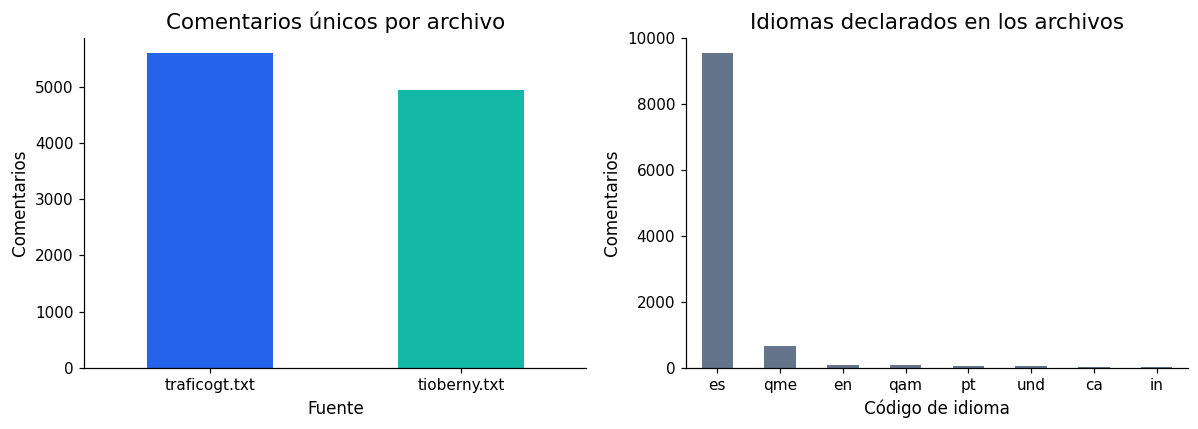

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
base['fuente'].value_counts().plot.bar(ax=axes[0], color=['#2563eb', '#14b8a6'], rot=0)
axes[0].set(title='Comentarios únicos por archivo', xlabel='Fuente', ylabel='Comentarios')
base['idioma'].value_counts().head(8).plot.bar(ax=axes[1], color='#64748b', rot=0)
axes[1].set(title='Idiomas declarados en los archivos', xlabel='Código de idioma', ylabel='Comentarios')
plt.tight_layout()
plt.show()

`tioberny.txt` aporta **899 comentarios (52.48%)** y `traficogt.txt`, **814 (47.52%)**.
La diferencia es de 85 comentarios, de modo que las dos fuentes tienen una participación
cercana en este lote. Para comparar las decisiones de moderación entre archivos conviene
usar también porcentajes, porque sus volúmenes no son iguales.

En la gráfica de idiomas predomina el código **es**, correspondiente al español.
También aparecen códigos como `qme`, `qam` y `und`, además de una cantidad menor
de comentarios con otros idiomas declarados. Las reglas cubren español e inglés;
los demás códigos pasan a revisión. Por ello, una parte de esa cola se debe a la
cobertura del sistema y no necesariamente a palabras ofensivas.

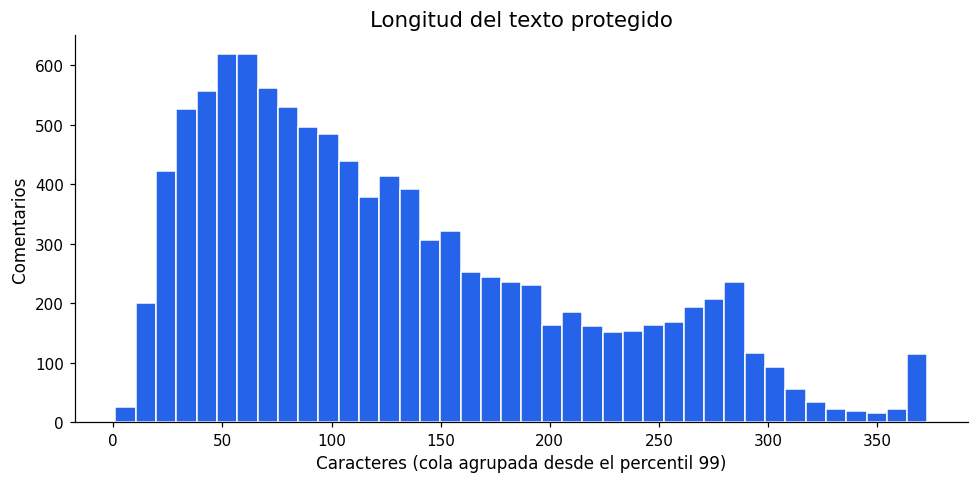

,texto_protegido
count,10539.0
mean,131.2
std,97.1
min,1.0
25%,61.0
50%,108.0
75%,182.0
max,2289.0


In [13]:
longitudes = base['texto_protegido'].str.len()
fig, ax = plt.subplots()
limite = longitudes.quantile(0.99)
ax.hist(longitudes.clip(upper=limite), bins=40, color='#2563eb', edgecolor='white')
ax.set(title='Longitud del texto protegido', xlabel='Caracteres (cola agrupada desde el percentil 99)', ylabel='Comentarios')
plt.tight_layout()
plt.show()
longitudes.describe().round(1)

La distribución de longitudes tiene una cola hacia la derecha: abundan los comentarios
breves y hay pocos textos mucho más largos. La mediana es de **116 caracteres**, mientras
que la media llega a **135.4**. El 50% central de los comentarios tiene entre **65 y 189
caracteres**, por lo que una revisión habitual implica leer textos de unas pocas frases.

El máximo registrado es de **1,064 caracteres**. Para evitar que esos valores alarguen
demasiado el eje horizontal, la gráfica agrupa la cola a partir del percentil 99;
por eso su último intervalo no coincide con el máximo de la tabla. La longitud ayuda
a describir la carga de lectura, aunque por sí sola no determina si un comentario es ofensivo.

## 6. Motor de reglas y lógica de negocio
Las comparaciones se hacen sin distinguir mayúsculas ni acentos. Se conservan las
negaciones porque una expresión como «no eres un idiota» necesita un tratamiento
distinto al de un insulto directo.

| Señal | Puntaje |
|---|---:|
| Grupo de insultos, como `stupid`, `idiota` o `estúpido` | 3 |
| Grupo de vulgaridades | 2 |
| Ataque personal explícito | 6 |
| Posible ataque discriminatorio | 6 |
| Posible amenaza explícita | 10 |
| Insulto dirigido (`eres`, `sos`, `you are`, etc.) | +3 |
| Cada término adicional distinto configurado | +3 |

Cada grupo suma una vez, aunque una palabra se repita en el comentario.
Las reglas se aplican en este orden:

1. Texto insuficiente o idioma no cubierto: **REVISAR**.
2. Amenaza o posible ataque discriminatorio: **REVISAR**, con prioridad alta.
3. Posible cita, negación o denuncia: **REVISAR**.
4. Puntaje de 6 o más, con ocultamiento automático activo: **OCULTAR**.
5. Puntaje de 2 o más: **REVISAR**.
6. Los demás casos: **PERMITIR**.

Los umbrales y los términos adicionales se pueden cambiar en el panel. El puntaje
expresa la suma de las reglas que coinciden con el texto.

In [14]:
def validar_config(config):
    if not 0 < config["umbral_revision"] < config["umbral_ocultar"]:
        raise ValueError("El umbral de revisión debe ser positivo y menor al de ocultamiento.")
    terminos = config.get("terminos_adicionales", [])
    if len(terminos) > 50 or any(not isinstance(t, str) or not t.strip() or len(t) > 50 for t in terminos):
        raise ValueError("Usa hasta 50 términos, de 1 a 50 caracteres cada uno.")


def huella_politica(config):
    contenido = {"version": VERSION, "config": config, "reglas": REGLAS}
    return hashlib.sha256(json.dumps(contenido, sort_keys=True).encode()).hexdigest()[:12]


def evaluar_texto(texto, idioma="es", config=None):
    config = {**CONFIG_DEFAULT, **(config or {})}
    validar_config(config)
    protegido, n_ocultos = enmascarar(texto)
    normal = normalizar(protegido)
    hallazgos = []
    for regla in REGLAS:
        coincidencias = sorted(set(re.findall(regla["patron"], normal)))
        if coincidencias:
            hallazgos.append({**regla, "coincidencias": coincidencias})
    for termino in sorted(set(normalizar(t) for t in config["terminos_adicionales"])):
        if re.search(r"(?<!\w)" + re.escape(termino) + r"(?!\w)", normal):
            hallazgos.append(dict(codigo="termino_adicional", categoria="Término configurado",
                                  peso=3, coincidencias=[termino]))
    codigos = {h["codigo"] for h in hallazgos}
    dirigido = bool(re.search(r"\b(?:eres|sos|sois|son|usted es|ustedes son|"
                              r"you are|youre|you're|callate|callense)\b", normal))
    puntaje = sum(h["peso"] for h in hallazgos)
    if dirigido and codigos.intersection({"insulto", "termino_adicional"}):
        puntaje += 3
    contexto = bool(hallazgos) and bool(re.search(
        r"\b(?:no (?:eres|sos|son|es|soy|somos|seas)|not|nunca dije|no dije|"
        r"la palabra|me dijeron|dijo|dijeron|denuncio|reporto)\b|[\"“”«»]", normal))
    fuera_cobertura = str(idioma).lower() not in {"es", "en"}
    sin_texto = not texto_util(protegido)
    critico = bool(codigos.intersection({"amenaza", "discriminacion"}))
    if sin_texto:
        decision, motivo = "REVISAR", "Sin texto suficiente para aplicar las reglas."
    elif fuera_cobertura:
        decision, motivo = "REVISAR", "Idioma no cubierto o indeterminado."
    elif critico:
        decision, motivo = "REVISAR", "Riesgo alto: requiere revisión prioritaria."
    elif contexto:
        decision, motivo = "REVISAR", "Posible cita, negación o denuncia: revisar contexto."
    elif puntaje >= config["umbral_ocultar"] and config["ocultar_automaticamente"]:
        decision, motivo = "OCULTAR", "Puntaje igual o superior al umbral de ocultamiento local."
    elif puntaje >= config["umbral_revision"]:
        decision, motivo = "REVISAR", "Puntaje igual o superior al umbral de revisión."
    else:
        decision, motivo = "PERMITIR", "No se alcanzó el umbral de revisión."
    categorias = list(dict.fromkeys(h["categoria"] for h in hallazgos))
    palabras = sorted({p for h in hallazgos for p in h["coincidencias"]})
    return dict(
        texto_protegido=protegido, datos_enmascarados=n_ocultos,
        puntaje=puntaje, categoria=" / ".join(categorias) or "Sin señales en las reglas",
        palabras_detectadas=", ".join(palabras), decision_motor=decision,
        prioridad="ALTA" if critico else "NORMAL", motivo=motivo,
        politica=huella_politica(config),
    )


def procesar_lote(base, config=None):
    evaluados = [evaluar_texto(r.texto_protegido, r.idioma, config)
                 for r in base.itertuples(index=False)]
    if not evaluados:
        columnas = ["puntaje", "categoria", "palabras_detectadas", "decision_motor",
                    "prioridad", "motivo", "politica"]
        return base.assign(**{c: pd.Series(dtype="object") for c in columnas})
    salida = pd.DataFrame(evaluados).drop(columns=["texto_protegido", "datos_enmascarados"])
    return pd.concat([base.reset_index(drop=True), salida], axis=1)

In [15]:
config = {**CONFIG_DEFAULT}
resultados = procesar_lote(base, config)
conteos = resultados['decision_motor'].value_counts().reindex(ACCIONES, fill_value=0)
tabla_decisiones = pd.DataFrame({
    'Comentarios': conteos,
    'Porcentaje del lote': (100 * conteos / len(resultados)).round(2),
})
print('Política aplicada:', huella_politica(config))
tabla_decisiones

Política aplicada: ba33b6033b5d


,Comentarios,Porcentaje del lote
decision_motor,,
PERMITIR,8921,84.65
REVISAR,1510,14.33
OCULTAR,108,1.02


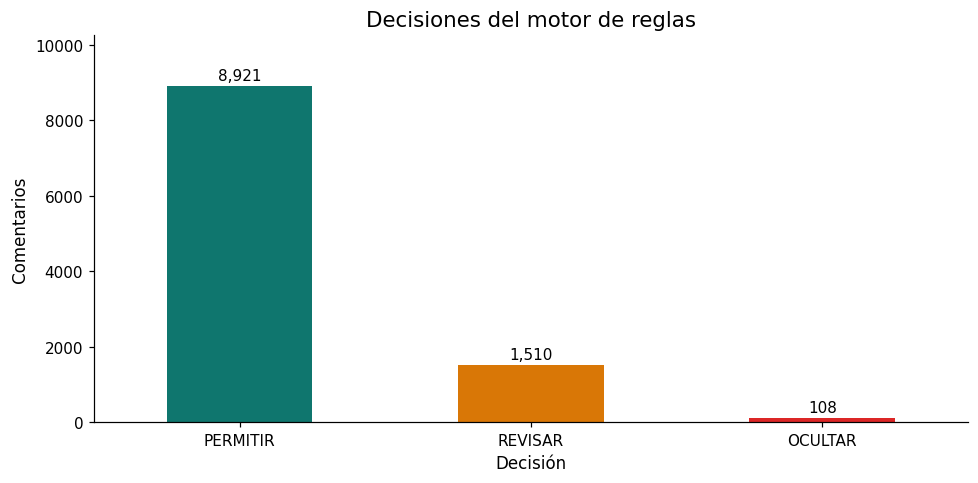

decision_motor,PERMITIR,REVISAR,OCULTAR
fuente,,,
tioberny.txt,4041,829,73
traficogt.txt,4880,681,35


In [16]:
fig, ax = plt.subplots()
conteos.plot.bar(ax=ax, color=[COLORES[a] for a in ACCIONES], rot=0)
ax.set(title='Decisiones del motor de reglas', ylabel='Comentarios', xlabel='Decisión')
for i, v in enumerate(conteos):
    ax.text(i, v + max(conteos) * 0.018, f'{v:,}', ha='center')
ax.set_ylim(0, max(conteos) * 1.15)
plt.tight_layout()
plt.show()
pd.crosstab(resultados['fuente'], resultados['decision_motor']).reindex(columns=ACCIONES, fill_value=0)

El motor permite **1,437 comentarios (83.89%)**, envía **263 a revisión (15.35%)** y
oculta **13 (0.76%)**. La mayor parte del lote queda por debajo del umbral de revisión.
Los 276 comentarios restantes, el 16.11%, quedan fuera de la vista pública mientras
se mantienen las decisiones actuales. Estos porcentajes describen el resultado de
las reglas y no la proporción de ciberacoso confirmada por una persona.

Por archivo, `tioberny.txt` tiene 147 casos de revisión y nueve ocultos, que juntos
equivalen al **17.35%** de sus comentarios. En `traficogt.txt` son 116 y cuatro,
respectivamente, el **14.74%**. La diferencia es de unos 2.61 puntos porcentuales.
La comparación incluye las derivaciones por idioma y falta de texto, por lo que
no permite atribuir toda la diferencia a una mayor presencia de insultos.

In [17]:
columnas = ['comentario_id', 'texto_protegido', 'categoria', 'puntaje', 'palabras_detectadas', 'decision_motor', 'motivo']
resultados.loc[resultados['palabras_detectadas'] != '', columnas].head(8)

,comentario_id,texto_protegido,categoria,puntaje,palabras_detectadas,decision_motor,motivo
116,c_d412013e489eaa703944,Ahora tuteamos a todos los de semilla para tra...,Lenguaje ofensivo,3,pendejos,REVISAR,Puntaje igual o superior al umbral de revisión.
134,c_423d2fe517ca3ab5e355,"[USUARIO] La IVE es un chiste, es una mierda.",Lenguaje vulgar,2,mierda,REVISAR,Puntaje igual o superior al umbral de revisión.
165,c_29c623033c465df76818,[USUARIO] Rata asquerosa. Sos la misma mierda ...,Lenguaje vulgar,2,"mierda, mierdas",REVISAR,Puntaje igual o superior al umbral de revisión.
169,c_dffa7afca1a48449237d,[USUARIO] Coman mierda hijos de puta.,Lenguaje vulgar / Ataque personal explícito,8,"hijos de puta, mierda, puta",OCULTAR,Puntaje igual o superior al umbral de ocultami...
176,c_b61aa32a2e18d5f39f05,[USUARIO] Oigan a este en verdad ni entendes d...,Lenguaje ofensivo,3,pendejo,REVISAR,Puntaje igual o superior al umbral de revisión.
189,c_8dcce03da841de89a01e,[USUARIO] Que enseñen sus facturas de cuando p...,Lenguaje vulgar,2,mierda,REVISAR,Puntaje igual o superior al umbral de revisión.
201,c_66b7dca27d6c40d4cec7,[USUARIO] Yo no soy responsable de decisiones ...,Lenguaje ofensivo,3,pendejas,REVISAR,"Posible cita, negación o denuncia: revisar con..."
202,c_36467b09a2393491f903,[USUARIO] 😂😂😂 es la excusa más estúpida para j...,Lenguaje ofensivo,3,estupida,REVISAR,Puntaje igual o superior al umbral de revisión.


Los ejemplos permiten seguir el cálculo de cada decisión. Una coincidencia con
`pendejo` o `pendejos` suma tres puntos y lleva el comentario a revisión; el grupo
de vulgaridades suma dos. El comentario con la expresión `hijos de puta` alcanza
ocho puntos al combinar vulgaridad y ataque personal explícito, y se oculta.
También aparece un caso enviado a revisión por una posible negación, aunque
contiene una palabra incluida en la lista de insultos.

## 7. Pruebas funcionales y de protección
Se prepararon once casos para comprobar el tratamiento de insultos, negaciones,
amenazas, menciones y críticas al servicio. También se verifica el enmascaramiento
de datos de contacto y la ausencia de IDs repetidos en el lote procesado.

In [18]:
casos = [
    ('stupid', 'en', 'REVISAR'),
    ('You are stupid', 'en', 'OCULTAR'),
    ('Sos un idiota', 'es', 'OCULTAR'),
    ('No eres un idiota', 'es', 'REVISAR'),
    ('Me dijeron "stupid"', 'en', 'REVISAR'),
    ('El servicio es lento y deben mejorar', 'es', 'PERMITIR'),
    ('Gracias por la información', 'es', 'PERMITIR'),
    ('Te voy a matar', 'es', 'REVISAR'),
    ('hello', 'fr', 'REVISAR'),
    ('@alguien https://ejemplo.com', 'es', 'REVISAR'),
    ('@stupid Muchas gracias', 'es', 'PERMITIR'),
]
pruebas = []
for texto, idioma, esperado in casos:
    salida = evaluar_texto(texto, idioma)
    pruebas.append({
        'Texto de prueba': texto, 'Esperado': esperado,
        'Obtenido': salida['decision_motor'], 'Categoría': salida['categoria'],
        'Coincide': salida['decision_motor'] == esperado,
    })
assert all(r['Coincide'] for r in pruebas)
print(f'{len(pruebas)} casos funcionales completados.')
pd.DataFrame(pruebas)

11 casos funcionales completados.


,Texto de prueba,Esperado,Obtenido,Categoría,Coincide
0,stupid,REVISAR,REVISAR,Lenguaje ofensivo,True
1,You are stupid,OCULTAR,OCULTAR,Lenguaje ofensivo,True
2,Sos un idiota,OCULTAR,OCULTAR,Lenguaje ofensivo,True
3,No eres un idiota,REVISAR,REVISAR,Lenguaje ofensivo,True
4,"Me dijeron ""stupid""",REVISAR,REVISAR,Lenguaje ofensivo,True
5,El servicio es lento y deben mejorar,PERMITIR,PERMITIR,Sin señales en las reglas,True
6,Gracias por la información,PERMITIR,PERMITIR,Sin señales en las reglas,True
7,Te voy a matar,REVISAR,REVISAR,Posible amenaza,True
8,hello,REVISAR,REVISAR,Sin señales en las reglas,True
9,@alguien https://ejemplo.com,REVISAR,REVISAR,Sin señales en las reglas,True


In [19]:
# Protección: el reporte no debe conservar los identificadores de esta prueba sintética.
texto_prueba = '@prueba correo persona@example.com teléfono +502 5555 1234 DPI 1234 56789 1234'
protegido, n = enmascarar(texto_prueba)
assert n == 4
assert 'persona@example.com' not in protegido
assert '5555 1234' not in protegido
assert '@prueba' not in protegido
assert '1234 56789 1234' not in protegido
assert not base['comentario_id'].duplicated().any()
print('Texto sintético protegido:', protegido)
print('IDs únicos y enmascaramiento básico verificados.')

Texto sintético protegido: [USUARIO] correo [CORREO] teléfono [TELEFONO] DPI [DPI]
IDs únicos y enmascaramiento básico verificados.


Los **once casos de prueba** produjeron la decisión esperada. `stupid` se reconoce
como lenguaje ofensivo y pasa a revisión; `You are stupid` suma el componente de
ataque dirigido y se oculta. `No eres un idiota` se revisa por la negación, mientras
que la crítica «El servicio es lento y deben mejorar» se permite. La mención
`@stupid` se enmascara antes de evaluar el texto y no suma puntos de insulto.
Estos casos comprueban el funcionamiento programado; la evaluación con comentarios
anotados por personas queda pendiente.

## 8. Automatización del flujo y revisión humana
La vista pública simulada incluye los comentarios permitidos. Los que requieren
revisión y los ocultos se conservan en colas separadas, con el texto protegido
y el motivo de la decisión. Una persona puede permitirlos u ocultarlos después
de revisar el contexto.

La bitácora guarda la fecha, el ID del comentario, la decisión anterior, la nueva
decisión, la justificación y la política aplicada. Una decisión humana se mantiene
durante el mismo lote y sesión, aunque cambien los umbrales. La bitácora debe
descargarse para conservar el registro al cerrar la sesión.

In [20]:
publicos = resultados[resultados['decision_motor'] == 'PERMITIR'].copy()
pendientes = resultados[resultados['decision_motor'] == 'REVISAR'].copy()
ocultos = resultados[resultados['decision_motor'] == 'OCULTAR'].copy()
assert len(publicos) + len(pendientes) + len(ocultos) == len(resultados)
print('Vista pública simulada:', len(publicos))
print('Cola de revisión:', len(pendientes))
print('Retirados de la vista por reglas:', len(ocultos))
publicos[['comentario_id', 'texto_protegido', 'fuente']].head(4)

Vista pública simulada: 8921
Cola de revisión: 1510
Retirados de la vista por reglas: 108


,comentario_id,texto_protegido,fuente
0,c_3f6cae93d197b144d0ba,Es comprensible la resolución... El ruso sabe ...,traficogt.txt
1,c_71e4349b75c5452b1b2f,"La corrupción de la [USUARIO]\nes descarada, f...",traficogt.txt
4,c_d3ea1629fe517fe593db,[USUARIO] [USUARIO] [USUARIO] [USUARIO] [USUAR...,traficogt.txt
5,c_d753d9bf8c08e7e55b7a,[USUARIO] [USUARIO] [USUARIO] [USUARIO] [USUAR...,traficogt.txt


In [21]:
# Ejemplo sintético separado del lote real: una negación requiere contexto.
ejemplo_revision = evaluar_texto('No eres un idiota', 'es')
bitacora_ejemplo = pd.DataFrame([{
    'fecha_utc': datetime.now(timezone.utc).isoformat(),
    'comentario_id': 'ejemplo_sintetico',
    'anterior': ejemplo_revision['decision_motor'],
    'nueva': 'PERMITIR',
    'justificacion': 'La frase niega el insulto en este ejemplo sintético.',
    'politica': huella_politica(config),
}])
bitacora_ejemplo

,fecha_utc,comentario_id,anterior,nueva,justificacion,politica
0,2026-11-20T16:46:52.270224+00:00,ejemplo_sintetico,REVISAR,PERMITIR,La frase niega el insulto en este ejemplo sint...,ba33b6033b5d


El ejemplo de bitácora registra el paso de **REVISAR** a **PERMITIR** para la frase
«No eres un idiota», junto con la justificación y la política aplicada. Se trata
de una frase de prueba, separada de los comentarios del lote. El registro permite
conservar el motivo de una intervención humana cuando el contexto cambia la decisión inicial.

## 9. Horas-hombre, costos y umbral financiero
    La comparación económica se calcula para el lote de 1,713 comentarios. Se utilizan
    los siguientes supuestos de tiempo y costo, que pueden ajustarse en la aplicación:

    | Parámetro | Valor |
    |---|---:|
    | Lectura manual por comentario | 45 segundos |
    | Revisión humana de un caso marcado | 45 segundos |
    | Auditoría de una decisión automática | 30 segundos |
    | Muestra de auditoría de decisiones automáticas | 10% |
    | Operación de la herramienta | 5 minutos por lote |
    | Costo de trabajo | Q35 por hora |
    | Costo de herramienta imputado | Q10 por lote |
    | Ahorro mínimo objetivo | 20% |

    Con $N$ comentarios, $N_r$ revisiones, $N_a=lceil(N-N_r)p/100
ceil$ auditorías,
    tiempos $t_m,t_r,t_a$ en segundos y $t_o$ en minutos:

    $$H_m=N t_m/3600$$
    $$H_a=(N_r t_r+N_a t_a)/3600+t_o/60$$
    $$C_m=H_m C_h,qquad C_a=H_a C_h+C_{herramienta}$$
    $$Ahorro=C_m-C_a,qquad Ahorro%=100(C_m-C_a)/C_m$$

    Se cumple el objetivo financiero cuando el ahorro es positivo y alcanza al menos
    el 20% del costo manual. Las cifras resultantes son una estimación; los tiempos
    de lectura y las tarifas deben medirse en la operación antes de proyectar un ahorro real.
    El cálculo no incorpora el costo de los errores de moderación.

In [22]:
def calcular_impacto(resultados, segundos_manual=45, segundos_revision=45,
                     segundos_auditoria=30, porcentaje_auditoria=10,
                     costo_hora=35, costo_herramienta_lote=10,
                     minutos_operacion=5, ahorro_objetivo_pct=20):
    valores = [segundos_manual, segundos_revision, segundos_auditoria, porcentaje_auditoria,
               costo_hora, costo_herramienta_lote, minutos_operacion, ahorro_objetivo_pct]
    if any(not math.isfinite(v) or v < 0 for v in valores):
        raise ValueError("Los parámetros financieros deben ser finitos y no negativos.")
    if porcentaje_auditoria > 100 or ahorro_objetivo_pct > 100:
        raise ValueError("Los porcentajes deben estar entre 0 y 100.")
    n = len(resultados)
    revisar = int((resultados["decision_motor"] == "REVISAR").sum())
    auditoria = math.ceil((n - revisar) * porcentaje_auditoria / 100)
    horas_manual = n * segundos_manual / 3600
    horas_asistido = ((revisar * segundos_revision + auditoria * segundos_auditoria) / 3600
                      + minutos_operacion / 60) if n else 0.0
    costo_manual = horas_manual * costo_hora
    costo_asistido = horas_asistido * costo_hora + (costo_herramienta_lote if n else 0)
    ahorro = costo_manual - costo_asistido
    ahorro_pct = 100 * ahorro / costo_manual if costo_manual else 0.0
    return dict(
        comentarios=n, revisiones=revisar, auditorias_muestreadas=auditoria,
        horas_manual=horas_manual, horas_asistido=horas_asistido,
        horas_ahorradas=horas_manual - horas_asistido,
        costo_manual_q=costo_manual, costo_asistido_q=costo_asistido,
        ahorro_q=ahorro, ahorro_pct=ahorro_pct,
        cumple_objetivo=bool(n and ahorro > 0 and ahorro_pct >= ahorro_objetivo_pct),
    )


def csv_seguro(df):
    """Evita interpretar el contenido del usuario como fórmula al abrir un CSV."""
    def proteger(valor):
        if isinstance(valor, str) and valor.lstrip().startswith(("=", "+", "-", "@")):
            return "'" + valor
        return valor
    protegido = df.copy()
    for columna in protegido:
        protegido[columna] = protegido[columna].map(proteger)
    return protegido.to_csv(index=False).encode("utf-8-sig")

In [23]:
impacto = calcular_impacto(resultados)
comparacion = pd.DataFrame({
    'Proceso': ['Manual', 'Asistido'],
    'Horas-hombre': [impacto['horas_manual'], impacto['horas_asistido']],
    'Costo estimado Q': [impacto['costo_manual_q'], impacto['costo_asistido_q']],
})
print(f"Horas potencialmente liberadas: {impacto['horas_ahorradas']:.2f}")
print(f"Ahorro neto hipotético: Q{impacto['ahorro_q']:,.2f} ({impacto['ahorro_pct']:.1f}%)")
print('Cumple el objetivo financiero:', impacto['cumple_objetivo'])
comparacion.round(2)

Horas potencialmente liberadas: 105.25
Ahorro neto hipotético: Q3,673.90 (79.7%)
Cumple el objetivo financiero: True


,Proceso,Horas-hombre,Costo estimado Q
0,Manual,131.74,4610.81
1,Asistido,26.48,936.92


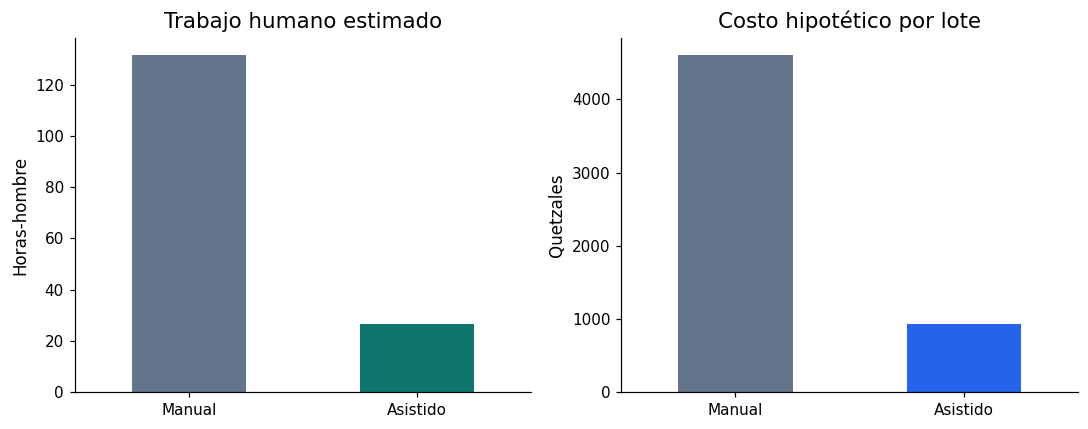

,Auditoría automática (%),Horas asistidas,Ahorro neto Q,Ahorro (%)
0,5,22.72,3805.44,82.53
1,10,26.48,3673.90,79.68
2,25,37.78,3278.69,71.11
3,100,94.20,1303.81,28.28


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
comparacion.plot.bar(x='Proceso', y='Horas-hombre', ax=axes[0], legend=False, color=['#64748b', '#0f766e'], rot=0)
axes[0].set(title='Trabajo humano estimado', ylabel='Horas-hombre', xlabel='')
comparacion.plot.bar(x='Proceso', y='Costo estimado Q', ax=axes[1], legend=False, color=['#64748b', '#2563eb'], rot=0)
axes[1].set(title='Costo hipotético por lote', ylabel='Quetzales', xlabel='')
plt.tight_layout()
plt.show()

sensibilidad = []
for porcentaje in [5, 10, 25, 100]:
    escenario = calcular_impacto(resultados, porcentaje_auditoria=porcentaje)
    sensibilidad.append({
        'Auditoría automática (%)': porcentaje,
        'Horas asistidas': escenario['horas_asistido'],
        'Ahorro neto Q': escenario['ahorro_q'],
        'Ahorro (%)': escenario['ahorro_pct'],
    })
pd.DataFrame(sensibilidad).round(2)

El trabajo humano estimado pasa de **21.41 a 4.58 horas** para el lote, una diferencia
de **16.83 horas**. El escenario asistido incluye la revisión de los **263 casos
pendientes**, la auditoría de **145 decisiones automáticas** y cinco minutos de operación.
Con Q35 por hora y Q10 de herramienta, el costo baja de **Q749.44 a Q170.27**.
El ahorro estimado es de **Q579.17**, equivalente al **77.28%**, y supera el objetivo del 20%.

La tabla de sensibilidad muestra cuánto depende el resultado del nivel de auditoría.
Al revisar una muestra del 5% de las decisiones automáticas, el ahorro estimado es de
**Q600.17**; con el 25%, disminuye a **Q515.58**. Con una auditoría del 100%, el trabajo
humano sube a **15.45 horas** y el ahorro baja a **Q198.54 (26.49%)**. En ese último caso,
todas las decisiones automáticas se vuelven a leer: el ahorro que permanece depende
del supuesto de que auditarlas toma 30 segundos, frente a los 45 segundos de la revisión manual.

## 10. Exportación, trazabilidad y validación pendiente
Se exportan el lote protegido, la vista pública simulada, las colas de revisión y
ocultamiento, las incidencias y el escenario económico. El archivo de política conserva
las reglas y los umbrales con los que se procesaron los comentarios. La exportación CSV
protege las celdas que podrían interpretarse como fórmulas al abrirse en una hoja de cálculo.

La plantilla de validación contiene **93 comentarios**: 40 tomados del grupo permitido,
40 del grupo de revisión y los 13 ocultos. La decisión del motor se omite en la plantilla
para que la persona que anote los textos haga su propia evaluación. Como la muestra
está estratificada, una estimación para el lote completo debe ponderar el tamaño de cada grupo.

In [25]:
SALIDAS = CARPETA / 'salidas'
SALIDAS.mkdir(exist_ok=True)
for nombre, tabla in [
    ('lote_moderado.csv', resultados),
    ('vista_publica_simulada.csv', publicos),
    ('cola_revision.csv', pendientes),
    ('ocultos.csv', ocultos),
    ('incidencias_ingesta.csv', incidencias),
]:
    (SALIDAS / nombre).write_bytes(csv_seguro(tabla))

muestras = [grupo.sample(n=min(40, len(grupo)), random_state=42)
            for _, grupo in resultados.groupby('decision_motor')]
muestra = pd.concat(muestras).sample(frac=1, random_state=42)[['comentario_id', 'texto_protegido']].copy()
muestra['etiqueta_humana'] = ''
muestra['justificacion'] = ''
(SALIDAS / 'plantilla_validacion_humana.csv').write_bytes(csv_seguro(muestra))
(SALIDAS / 'politica_moderacion.json').write_text(json.dumps(
    {'version': VERSION, 'huella': huella_politica(config), 'config': config, 'reglas': REGLAS},
    ensure_ascii=False, indent=2), encoding='utf-8')
(SALIDAS / 'impacto_estimado.json').write_text(json.dumps(impacto, indent=2), encoding='utf-8')
print('Archivos generados en salidas/:')
print('\n'.join(p.name for p in sorted(SALIDAS.iterdir()) if p.is_file()))
print('Comentarios para anotación humana:', len(muestra))

Archivos generados en salidas/:
cola_revision.csv
impacto_estimado.json
incidencias_ingesta.csv
lote_moderado.csv
ocultos.csv
plantilla_validacion_humana.csv
politica_moderacion.json
vista_publica_simulada.csv
Comentarios para anotación humana: 120


## 11. Resultados, limitaciones y siguientes pasos

In [26]:
print(f"Se procesaron {len(base):,} comentarios únicos de los archivos entregados.")
print(f"El motor permite {len(publicos):,}, envía a revisión {len(pendientes):,} y oculta {len(ocultos):,}.")
print(f"Se registraron {len(incidencias)} incidencias de ingesta y {int(base.datos_enmascarados.sum()):,} enmascaramientos.")
print(f"Bajo los supuestos del ejemplo, el ahorro potencial por lote es Q{impacto['ahorro_q']:,.2f}.")
print('Estos conteos describen reglas aplicadas, no decisiones verificadas por anotadores.')

Se procesaron 10,539 comentarios únicos de los archivos entregados.
El motor permite 8,921, envía a revisión 1,510 y oculta 108.
Se registraron 85 incidencias de ingesta y 30,120 enmascaramientos.
Bajo los supuestos del ejemplo, el ahorro potencial por lote es Q3,673.90.
Estos conteos describen reglas aplicadas, no decisiones verificadas por anotadores.


### Conclusiones
De los 1,713 comentarios procesados, 1,437 quedaron disponibles en la vista pública,
263 pasaron a revisión y 13 se ocultaron por las reglas configuradas. La lectura inicial
del equipo se concentra así en el 15.35% del lote, además de la muestra de auditoría.
La revisión sigue siendo necesaria para interpretar citas, negaciones y expresiones
que una coincidencia de palabras no resuelve.

Con los tiempos y costos planteados, el proceso asistido requiere 16.83 horas menos
y reduce el costo estimado en Q579.17. El análisis de sensibilidad muestra que ese
resultado cambia al aumentar la auditoría, por lo que la decisión de automatizar
debe considerar tanto el tiempo disponible como el nivel de control que necesita el equipo.

Los archivos no contienen etiquetas humanas de ofensividad. Queda pendiente anotar
una muestra y revisar los falsos positivos y negativos antes de afirmar qué tan bien
detecta el sistema los comentarios ofensivos. El alcance actual comprende el filtrado
de archivos y el registro de decisiones; una operación en redes requiere integrar
la plataforma y definir permisos y almacenamiento permanente.